Task 1

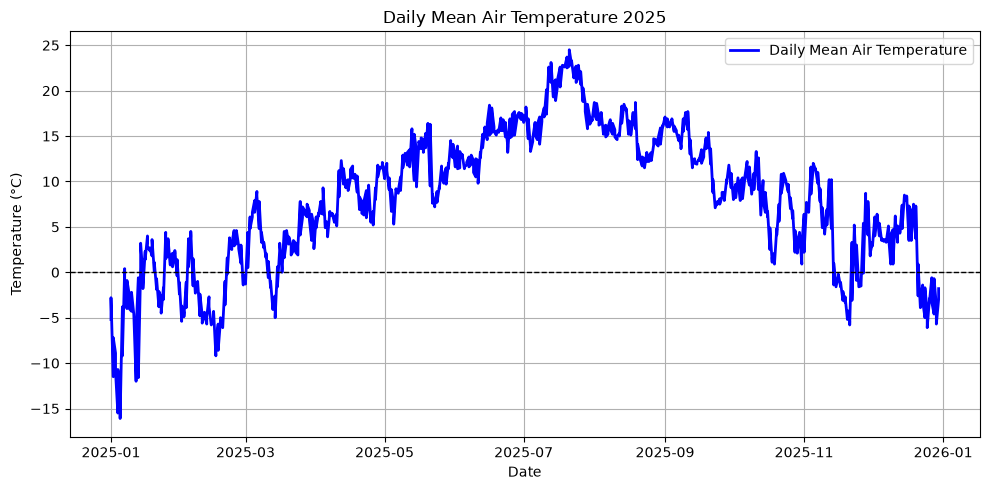

In [9]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Reading the client ID from a local file
client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Issuing a HTTP GET request to the Frost API with the specified parameters and authentication
r = requests.get(endpoint, params=parameters, auth=(client_id, ""))
json_data = r.json()

# Checking if the request was successful
if r.status_code == 200:
    # Extracting the relevant data
    data = json_data["data"]

    # Flattening the data into a list of dictionaries
    rows = []
    for entry in data:
        ref_time = entry["referenceTime"]
        for observation in entry["observations"]:
            rows.append(
                {"datetime": ref_time, "temperature": observation["value"]}
            )

    # Creating a DataFrame
    df = pd.DataFrame(rows)
    df["datetime"] = pd.to_datetime(df["datetime"])

    # Using matplotlib to plot the data
    plt.figure(figsize=(10, 5))
    plt.plot(
        df["datetime"],
        df["temperature"],
        color="blue",
        linewidth=2,
        label="Daily Mean Air Temperature",
    )
    plt.axhline(0, color="black", linewidth=1, linestyle="--")

    plt.title("Daily Mean Air Temperature 2025")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.grid()
    plt.legend()
    plt.tight_layout()

    # Displaying the plot
    plt.show()

else:
    print(f"Error {r.status_code}: {json_data.get('error', {}).get('message')}")

Task 2

In [ ]:
import os
import requests
import pandas as pd


client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'sum(precipitation_amount P1D),mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

https_req = requests.get(endpoint, parameters, auth=(client_id,''))
json = https_req.json()

if https_req.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % https_req.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])